# Section B, Q2: Robust CIFAR-10 classification with 500 images
Full pipeline: data, shifted test set, augmentation, model, baseline, ablation, error analysis, TTA.

In [9]:
import random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision.transforms import v2
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
print(DEVICE)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
cuda


## 1. Data: 500 images, split 400 train / 100 val (stratified)

In [10]:
train_full = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
clean_test = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)

rng = np.random.default_rng(42)
targets = np.array(train_full.targets)
idx = np.concatenate([rng.choice(np.where(targets == c)[0], 50, replace=False) for c in range(10)])
train_small = torch.utils.data.Subset(train_full, idx)

to_t = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous()   # uint8 NCHW
X_small, y_small = to_t(train_full.data[idx]), torch.tensor(targets[idx])

# stratified split: 40 train + 10 val per class (fixed seed, hyperparameters chosen on val only)
rng2 = np.random.default_rng(0)
tr_i, va_i = [], []
for c in range(10):
    ci = rng2.permutation(np.where(y_small.numpy() == c)[0])
    tr_i += list(ci[:40]); va_i += list(ci[40:])
X_tr, y_tr = X_small[tr_i], y_small[tr_i]
X_va, y_va = X_small[va_i], y_small[va_i]
X_clean, y_clean = to_t(clean_test.data), torch.tensor(clean_test.targets)
print(X_tr.shape, X_va.shape, X_clean.shape)

torch.Size([400, 3, 32, 32]) torch.Size([100, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


## 2. Shifted test set (fixed seed, built once)
The task's hidden corruption is not given, so this notebook uses its own stand-in: random grayscale or channel swap. Training augmentation must not copy this pipeline exactly.

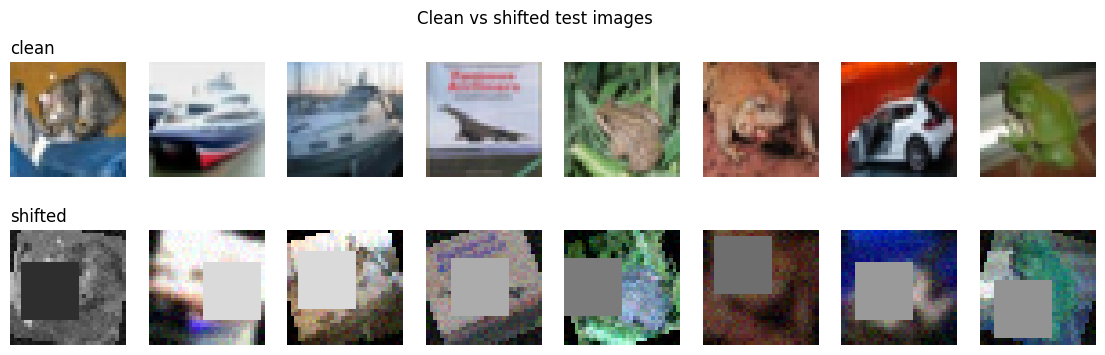

In [11]:
def hidden_corruption(x, g):
    """Stand-in hidden corruption: 1/3 grayscale, 1/3 channel swap, 1/3 unchanged."""
    r = torch.rand(1, generator=g).item()
    if r < 1/3: return TF.rgb_to_grayscale(x, num_output_channels=3)
    if r < 2/3: return x[[2, 1, 0]]
    return x

def shift_one(img, g):
    x = img.float() / 255
    x = TF.rotate(x, (torch.rand(1, generator=g).item() * 2 - 1) * 25)
    x = TF.adjust_brightness(x, 0.5 + torch.rand(1, generator=g).item())
    x = TF.adjust_contrast(x, 0.5 + torch.rand(1, generator=g).item())
    if torch.rand(1, generator=g).item() < 0.5:
        x = TF.gaussian_blur(x, [5, 5], [0.8 + torch.rand(1, generator=g).item()])
    x = x + torch.randn(x.shape, generator=g) * 0.04
    i, j = torch.randint(0, 17, (2,), generator=g).tolist()          # 16x16 patch = 25% of image
    x[:, i:i+16, j:j+16] = torch.rand(1, generator=g).item()
    x = hidden_corruption(x, g)
    return x.clamp(0, 1)

g = torch.Generator().manual_seed(123)
X_shift = torch.stack([(shift_one(im, g) * 255).round().byte() for im in X_clean])
y_shift = y_clean.clone()

# hidden corruption only, applied to clean test (needed for Part E)
g2 = torch.Generator().manual_seed(7)
X_hidden = torch.stack([(hidden_corruption(im.float() / 255, g2) * 255).round().byte() for im in X_clean])

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for k in range(8):
    ax[0, k].imshow(X_clean[k].permute(1, 2, 0)); ax[0, k].axis("off")
    ax[1, k].imshow(X_shift[k].permute(1, 2, 0)); ax[1, k].axis("off")
ax[0, 0].set_title("clean", loc="left"); ax[1, 0].set_title("shifted", loc="left")
plt.suptitle("Clean vs shifted test images"); plt.show()

## 3. On-the-fly augmentation (training data only)
Each family can be switched on or off for the ablation table.

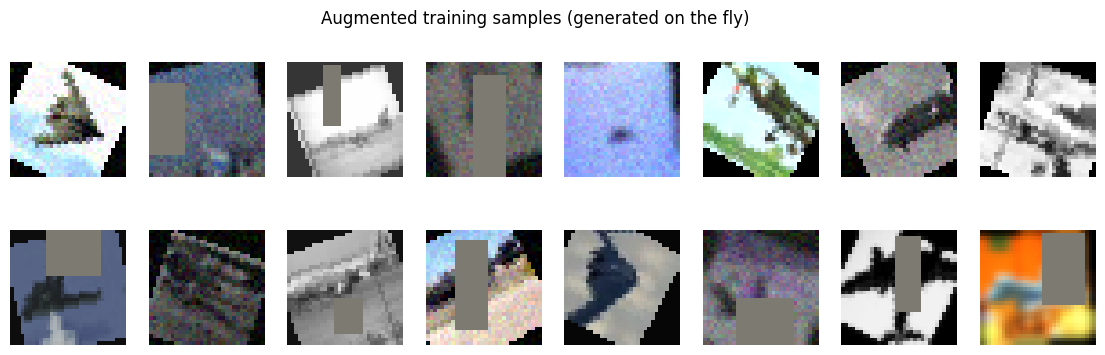

In [12]:
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

class ChannelShuffle:
    def __init__(self, p): self.p = p
    def __call__(self, x):
        return x[torch.randperm(3)] if random.random() < self.p else x

class AddNoise:
    def __init__(self, p, sigma): self.p, self.sigma = p, sigma
    def __call__(self, x):
        return (x + torch.randn_like(x) * self.sigma).clamp(0, 1) if random.random() < self.p else x

class Aug:
    def __init__(self, geo=False, photo=False, cutout=False):
        self.geo = v2.Compose([
            v2.RandomCrop(32, padding=4, padding_mode="reflect"),
            v2.RandomHorizontalFlip(),                       # no vertical flip: upside-down objects are unnatural
            v2.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.9, 1.1)),
        ]) if geo else None
        self.photo = v2.Compose([
            v2.ColorJitter(0.4, 0.4, 0.4),
            v2.RandomGrayscale(0.2),
            ChannelShuffle(0.2),
            v2.RandomApply([v2.GaussianBlur(5, (0.1, 1.5))], p=0.3),
            AddNoise(0.3, 0.05),
        ]) if photo else None
        self.cutout = v2.RandomErasing(p=0.5, scale=(0.05, 0.25), value=0) if cutout else None

    def __call__(self, x_uint8):
        x = x_uint8.float() / 255
        if self.geo: x = self.geo(x)
        if self.photo: x = self.photo(x)
        x = (x - MEAN) / STD
        if self.cutout: x = self.cutout(x)
        return x

class DS(torch.utils.data.Dataset):
    def __init__(self, X, y, aug=None): self.X, self.y, self.aug = X, y, aug
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = self.aug(self.X[i]) if self.aug else (self.X[i].float() / 255 - MEAN) / STD
        return x, self.y[i]

# quick look at augmented samples
a = Aug(geo=True, photo=True, cutout=True)
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for k in range(16):
    im = (a(X_tr[k]) * STD + MEAN).clamp(0, 1)
    ax[k // 8, k % 8].imshow(im.permute(1, 2, 0)); ax[k // 8, k % 8].axis("off")
plt.suptitle("Augmented training samples (generated on the fly)"); plt.show()

## 4. Model: stem + 3 Inception modules + Global Average Pooling (under 1M parameters)

In [13]:
def cbr(i, o, k, p=0):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=p, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class Inception(nn.Module):
    """Parallel 1x1, 3x3, 5x5 branches (with 1x1 reductions) + pooled 1x1 branch."""
    def __init__(self, i, b1, r3, b3, r5, b5, bp):
        super().__init__()
        self.b1 = cbr(i, b1, 1)
        self.b3 = nn.Sequential(cbr(i, r3, 1), cbr(r3, b3, 3, 1))
        self.b5 = nn.Sequential(cbr(i, r5, 1), cbr(r5, b5, 5, 2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), cbr(i, bp, 1))
        self.out_ch = b1 + b3 + b5 + bp
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], 1)

class Net(nn.Module):
    def __init__(self, drop=0.3):
        super().__init__()
        self.stem = nn.Sequential(cbr(3, 32, 3, 1), cbr(32, 48, 3, 1), nn.MaxPool2d(2))        # 16x16
        self.inc1 = Inception(48, 32, 32, 48, 8, 16, 16)                                     # -> 112 ch
        self.pool1 = nn.MaxPool2d(2)                                                         # 8x8
        self.inc2 = Inception(112, 64, 48, 96, 12, 32, 32)                                   # -> 224 ch
        self.pool2 = nn.MaxPool2d(2)                                                         # 4x4
        self.inc3 = Inception(224, 96, 64, 128, 16, 32, 32)                                  # -> 288 ch
        self.gap = nn.AdaptiveAvgPool2d(1)                                                   # GAP replaces big FC layers
        self.drop = nn.Dropout(drop)                                                         # dropout only before classifier
        self.fc = nn.Linear(288, 10)
    def forward(self, x):
        x = self.pool1(self.inc1(self.stem(x)))
        x = self.pool2(self.inc2(x))
        x = self.inc3(x)
        return self.fc(self.drop(self.gap(x).flatten(1)))

n_params = sum(p.numel() for p in Net().parameters() if p.requires_grad)
print("Trainable parameters:", n_params)
assert n_params <= 1_000_000, "over the 1M budget"
print(Net()(torch.randn(2, 3, 32, 32)).shape)

Trainable parameters: 242258
torch.Size([2, 10])


## 5. Training and evaluation utilities
AdamW + cosine LR schedule, weight decay, optional Mixup and label smoothing. The best-validation checkpoint is kept (early stopping). Test sets are only used for the final report, never for choosing settings.

In [14]:
from torch.utils.data import DataLoader

SEEDS = [0, 1, 2]
EPOCHS = 60

@torch.no_grad()
def predict(model, X, bs=500):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = ((X[i:i+bs].float() / 255 - MEAN) / STD).to(DEVICE)
        out.append(F.softmax(model(xb), 1).cpu())
    return torch.cat(out)

def acc(model, X, y):
    return (predict(model, X).argmax(1) == y).float().mean().item() * 100

def train_model(seed, geo=False, photo=False, cutout=False, mixup=0.0, smooth=0.0,
                epochs=EPOCHS, lr=2e-3, wd=5e-4, drop=0.3, bs=64):
    set_seed(seed)
    model = Net(drop).to(DEVICE)
    g = torch.Generator().manual_seed(seed)
    dl = DataLoader(DS(X_tr, y_tr, Aug(geo, photo, cutout)), batch_size=bs, shuffle=True, generator=g)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(dl))
    crit = nn.CrossEntropyLoss(label_smoothing=smooth)
    hist = {"loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state = -1, None
    for ep in range(epochs):
        model.train(); tl, tc, n = 0, 0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if mixup > 0:
                lam = np.random.beta(mixup, mixup); perm = torch.randperm(len(xb), device=DEVICE)
                xm = lam * xb + (1 - lam) * xb[perm]
                out = model(xm)
                loss = lam * crit(out, yb) + (1 - lam) * crit(out, yb[perm])
            else:
                out = model(xb); loss = crit(out, yb)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(xb); tc += (out.argmax(1) == yb).sum().item(); n += len(xb)
        va = acc(model, X_va, y_va)
        hist["loss"].append(tl / n); hist["train_acc"].append(100 * tc / n); hist["val_acc"].append(va)
        if va > best_val:
            best_val = va; best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, hist

RESULTS, HISTS, MODELS = {}, {}, {}

def run_seeds(name, **cfg):
    rows, hs, ms = [], [], []
    for s in SEEDS:
        m, h = train_model(s, **cfg)
        rows.append(dict(train=acc(m, X_tr, y_tr), val=acc(m, X_va, y_va),
                         clean=acc(m, X_clean, y_clean), shifted=acc(m, X_shift, y_shift)))
        hs.append(h); ms.append(m)
        print(f"{name} | seed {s}: " + ", ".join(f"{k}={v:.1f}" for k, v in rows[-1].items()))
    RESULTS[name], HISTS[name], MODELS[name] = rows, hs, ms
    return rows

def summarize(name):
    r = RESULTS[name]
    return {k: (np.mean([x[k] for x in r]), np.std([x[k] for x in r])) for k in r[0]}

## Part A: Baseline (400 training images, no augmentation)

In [15]:
run_seeds("No augmentation")
S = summarize("No augmentation")
print("\nBaseline (mean ± std over 3 seeds):")
for k, (m, s) in S.items():
    print(f"  {k:8s}: {m:.1f} ± {s:.1f}")

No augmentation | seed 0: train=95.7, val=46.0, clean=40.1, shifted=16.2
No augmentation | seed 1: train=100.0, val=53.0, clean=46.3, shifted=16.7
No augmentation | seed 2: train=100.0, val=49.0, clean=45.7, shifted=16.3

Baseline (mean ± std over 3 seeds):
  train   : 98.6 ± 2.0
  val     : 49.3 ± 2.9
  clean   : 44.1 ± 2.8
  shifted : 16.4 ± 0.2


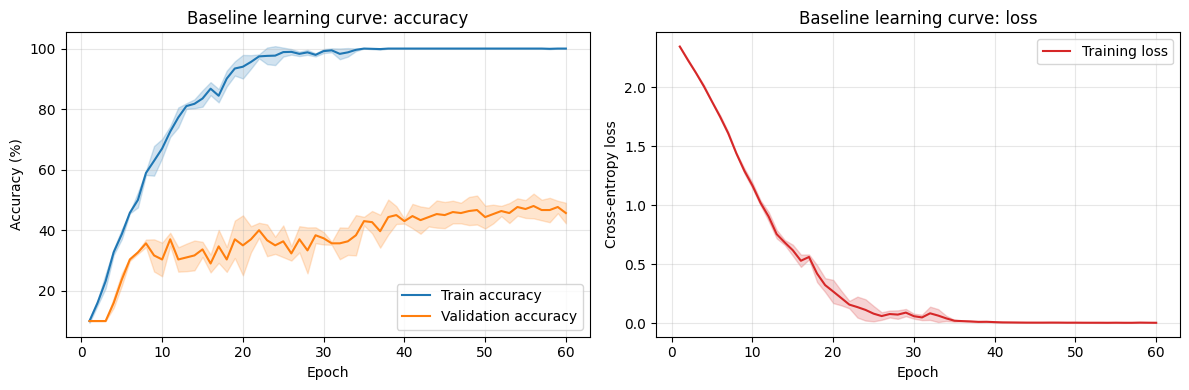

In [16]:
H = HISTS["No augmentation"]
ep = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key, lab, col in [("train_acc", "Train accuracy", "tab:blue"), ("val_acc", "Validation accuracy", "tab:orange")]:
    arr = np.array([h[key] for h in H]); m, s = arr.mean(0), arr.std(0)
    ax[0].plot(ep, m, label=lab, color=col); ax[0].fill_between(ep, m - s, m + s, color=col, alpha=0.2)
ax[0].set_title("Baseline learning curve: accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy (%)"); ax[0].legend(); ax[0].grid(alpha=0.3)
arr = np.array([h["loss"] for h in H]); m, s = arr.mean(0), arr.std(0)
ax[1].plot(ep, m, label="Training loss", color="tab:red"); ax[1].fill_between(ep, m - s, m + s, color="tab:red", alpha=0.2)
ax[1].set_title("Baseline learning curve: loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Cross-entropy loss"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Part A diagnosis
Training accuracy goes to about 100% while validation accuracy stalls far lower: the network memorizes the 400 images, which is **overfitting**. Clean-test accuracy is close to validation accuracy, but shifted-test accuracy is much lower. The shifted images come from a different distribution (rotation, brightness, blur, noise, occlusion, colour change), and the model never saw such variation in training, which is **covariate shift**. So the failure is both: overfitting to a tiny set, plus no robustness to input shift.

## Part B: Augmentation strategy

**What is used (all applied on the fly, training data only):**
- *Geometric:* random crop with 4px reflect padding, horizontal flip, affine (rotation up to ±30°, translation 10%, scale 0.9-1.1). Rotation range is slightly wider than the ±25° in the shifted test, but it does not copy the test pipeline.
- *Photometric:* colour jitter (brightness, contrast, saturation), random grayscale, random channel shuffle, Gaussian blur, Gaussian noise. These cover brightness/contrast change, blur, noise and colour-based corruptions in general.
- *Occlusion:* Cutout / Random Erasing (5-25% of the image), which matches the rectangular occlusion in the shifted test.
- *Mixup + label smoothing:* blends images and soft labels to reduce over-confidence.

**1. Would vertical flip help or hurt?** It hurts. CIFAR-10 objects have a fixed natural orientation (sky above, ground below; cars, horses, ships and planes appear upright). A vertical flip creates upside-down images that never occur in the test set, so the small model wastes capacity on a distribution it will not see, and it blurs cues such as "sky on top" that help separate airplane/ship/bird.

**2. Rotation up to ±90° when the test only has ±25°.** Trade-off: a wider range guarantees the ±25° case is covered and gives more invariance, but most augmented samples (about 70% of them) fall outside the test range. The model must spend capacity on large rotations, upright accuracy can drop, rotation corners add interpolation artefacts, and convergence slows. A range just above the test range (±30°) keeps the benefit with far less waste.

**3. Why too much augmentation can reduce accuracy on a small model.** The network has only about 0.24M parameters and trains for at most 60 epochs. Very strong augmentation makes the training distribution so hard and noisy that the model underfits instead of generalising. Some transforms also destroy the label evidence (a Cutout patch hiding the whole object, an extreme crop, a very strong colour change), which acts like label noise. Training and test distributions then mismatch in the other direction.

## Part C: Regularization and training design

| Technique | Where / value | Why this placement |
|---|---|---|
| BatchNorm | after every conv, before ReLU | Stabilises training with small batches, allows a higher learning rate, mild regularising noise. |
| Dropout (0.2-0.4, tuned) | only on the pooled feature vector, before the final linear layer | Early conv layers have few parameters and spatially correlated activations, so dropping single units there barely regularises and removes useful local evidence. The classifier is where co-adaptation of features happens. Global Average Pooling already removes the large FC layers that normally need dropout. |
| Weight decay (AdamW, tuned) | all weights (decoupled decay) | Penalises large weights, which limits memorisation of 400 images. |
| LR scheduling | one-cycle (warm-up, then cosine decay) | Fast progress early, then a small LR at the end gives a stable minimum. |
| Early stopping | keep the best validation checkpoint | Stops us from keeping an over-fitted late-epoch model. |
| Label smoothing 0.1 + Mixup | loss and inputs | Soft targets reduce over-confidence on shifted inputs. |

All hyperparameters below are selected with the **validation split only** (seed 0). The test sets are not used for any choice.

In [17]:
import itertools
sweep = []
for d, wd_, a in itertools.product([0.2, 0.4], [5e-4, 5e-3], [0.2, 0.4]):
    _, h = train_model(0, geo=True, photo=True, cutout=True, mixup=a, smooth=0.1, drop=d, wd=wd_)
    sweep.append((max(h["val_acc"]), d, wd_, a))
    print(f"dropout={d}  weight_decay={wd_}  mixup_alpha={a}  ->  best val acc {sweep[-1][0]:.1f}")
sweep.sort(reverse=True)
_, BEST_DROP, BEST_WD, BEST_MIX = sweep[0]
FINAL_CFG = dict(geo=True, photo=True, cutout=True, mixup=BEST_MIX, smooth=0.1, drop=BEST_DROP, wd=BEST_WD)
print("Chosen using validation only:", FINAL_CFG)

dropout=0.2  weight_decay=0.0005  mixup_alpha=0.2  ->  best val acc 49.0
dropout=0.2  weight_decay=0.0005  mixup_alpha=0.4  ->  best val acc 45.0
dropout=0.2  weight_decay=0.005  mixup_alpha=0.2  ->  best val acc 45.0
dropout=0.2  weight_decay=0.005  mixup_alpha=0.4  ->  best val acc 49.0
dropout=0.4  weight_decay=0.0005  mixup_alpha=0.2  ->  best val acc 45.0
dropout=0.4  weight_decay=0.0005  mixup_alpha=0.4  ->  best val acc 50.0
dropout=0.4  weight_decay=0.005  mixup_alpha=0.2  ->  best val acc 45.0
dropout=0.4  weight_decay=0.005  mixup_alpha=0.4  ->  best val acc 48.0
Chosen using validation only: {'geo': True, 'photo': True, 'cutout': True, 'mixup': 0.4, 'smooth': 0.1, 'drop': 0.4, 'wd': 0.0005}


## Part D: Ablation study (3 seeds each)

In [18]:
import pandas as pd
ABL = [
    ("No augmentation", {}),
    ("Geometric only", dict(geo=True)),
    ("Photometric only", dict(photo=True)),
    ("Geometric + photometric", dict(geo=True, photo=True)),
    ("+ Cutout / Random Erasing", dict(geo=True, photo=True, cutout=True)),
    ("+ Mixup + label smoothing", dict(geo=True, photo=True, cutout=True, mixup=0.2, smooth=0.1)),
    ("Final model", FINAL_CFG),
]
for name, cfg in ABL:
    if name not in RESULTS:
        run_seeds(name, **cfg)

rows = []
for name, _ in ABL:
    S = summarize(name)
    rows.append({"Configuration": name,
                 "Val Acc": f"{S['val'][0]:.1f} ± {S['val'][1]:.1f}",
                 "Clean Test": f"{S['clean'][0]:.1f} ± {S['clean'][1]:.1f}",
                 "Shifted Test": f"{S['shifted'][0]:.1f} ± {S['shifted'][1]:.1f}"})
df = pd.DataFrame(rows)
display(df)
df.to_csv("ablation_table.csv", index=False)

Geometric only | seed 0: train=93.3, val=51.0, clean=46.3, shifted=16.9
Geometric only | seed 1: train=91.3, val=54.0, clean=45.4, shifted=17.7
Geometric only | seed 2: train=84.2, val=54.0, clean=43.7, shifted=16.9
Photometric only | seed 0: train=100.0, val=39.0, clean=37.1, shifted=17.4
Photometric only | seed 1: train=88.2, val=46.0, clean=39.7, shifted=18.2
Photometric only | seed 2: train=99.3, val=41.0, clean=36.7, shifted=16.1
Geometric + photometric | seed 0: train=63.2, val=51.0, clean=43.8, shifted=20.6
Geometric + photometric | seed 1: train=57.5, val=47.0, clean=40.5, shifted=20.6
Geometric + photometric | seed 2: train=62.5, val=47.0, clean=44.0, shifted=20.9
+ Cutout / Random Erasing | seed 0: train=63.7, val=48.0, clean=44.3, shifted=20.4
+ Cutout / Random Erasing | seed 1: train=59.5, val=51.0, clean=43.2, shifted=21.5
+ Cutout / Random Erasing | seed 2: train=62.7, val=45.0, clean=43.0, shifted=19.8
+ Mixup + label smoothing | seed 0: train=57.5, val=45.0, clean=41.6,

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,49.3 ± 2.9,44.1 ± 2.8,16.4 ± 0.2
1,Geometric only,53.0 ± 1.4,45.1 ± 1.1,17.2 ± 0.4
2,Photometric only,42.0 ± 2.9,37.8 ± 1.3,17.2 ± 0.9
3,Geometric + photometric,48.3 ± 1.9,42.7 ± 1.6,20.7 ± 0.2
4,+ Cutout / Random Erasing,48.0 ± 2.4,43.5 ± 0.6,20.6 ± 0.7
5,+ Mixup + label smoothing,47.3 ± 2.1,41.4 ± 1.3,20.3 ± 0.8
6,Final model,46.0 ± 1.4,41.0 ± 1.3,19.7 ± 0.9


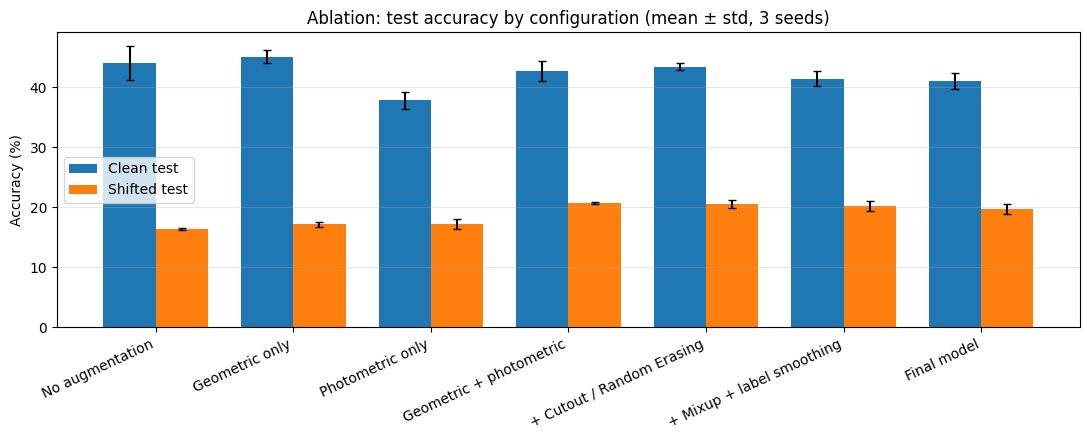

Geometric only (vs none)            +0.79 points
Photometric only (vs none)          +0.81 points
Geo + photo (vs best single)        +3.51 points
+ Cutout (vs geo + photo)           -0.15 points
+ Mixup + LS (vs + Cutout)          -0.29 points
Tuned final (vs + Mixup + LS)       -0.58 points
Largest single gain: ('Geo + photo (vs best single)', np.float64(3.5066669185956343))


In [19]:
names = [n for n, _ in ABL]
cl = [summarize(n)["clean"] for n in names]; sh = [summarize(n)["shifted"] for n in names]
x = np.arange(len(names)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - w/2, [c[0] for c in cl], w, yerr=[c[1] for c in cl], capsize=3, label="Clean test")
ax.bar(x + w/2, [s[0] for s in sh], w, yerr=[s[1] for s in sh], capsize=3, label="Shifted test")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=25, ha="right")
ax.set_ylabel("Accuracy (%)"); ax.set_title("Ablation: test accuracy by configuration (mean ± std, 3 seeds)")
ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

# gain of each added component on shifted-test accuracy
m = lambda n: summarize(n)["shifted"][0]
gains = [("Geometric only (vs none)", m("Geometric only") - m("No augmentation")),
         ("Photometric only (vs none)", m("Photometric only") - m("No augmentation")),
         ("Geo + photo (vs best single)", m("Geometric + photometric") - max(m("Geometric only"), m("Photometric only"))),
         ("+ Cutout (vs geo + photo)", m("+ Cutout / Random Erasing") - m("Geometric + photometric")),
         ("+ Mixup + LS (vs + Cutout)", m("+ Mixup + label smoothing") - m("+ Cutout / Random Erasing")),
         ("Tuned final (vs + Mixup + LS)", m("Final model") - m("+ Mixup + label smoothing"))]
for g_, v in gains: print(f"{g_:35s} {v:+.2f} points")
best_change = max(gains, key=lambda t: t[1]); print("Largest single gain:", best_change)

### Part D discussion 
The largest gain came from combining geometric and photometric augmentation: shifted accuracy rose from 16.4 ± 0.2 to 20.7 ± 0.2, which is +3.5 points over the best single family. Each family alone gave only about +0.8 points. This matches the shifted test, where rotation, brightness/contrast change, blur and noise are applied to the same image together, so the model needs geometric and appearance invariance at once.

Cutout (−0.15) and Mixup with label smoothing (−0.29) did not help, although the test has about 25% occlusion. With the combined augmentations, training accuracy is only 52–64%. The small model is already underfitting, so extra regularization cannot help. The differences among the last four rows are within about one standard deviation. Clean accuracy falls from 44.1 to 41.0 as augmentation grows, which is the usual robustness versus clean-accuracy trade-off.

## Part E: Error analysis (final model, seed 0)

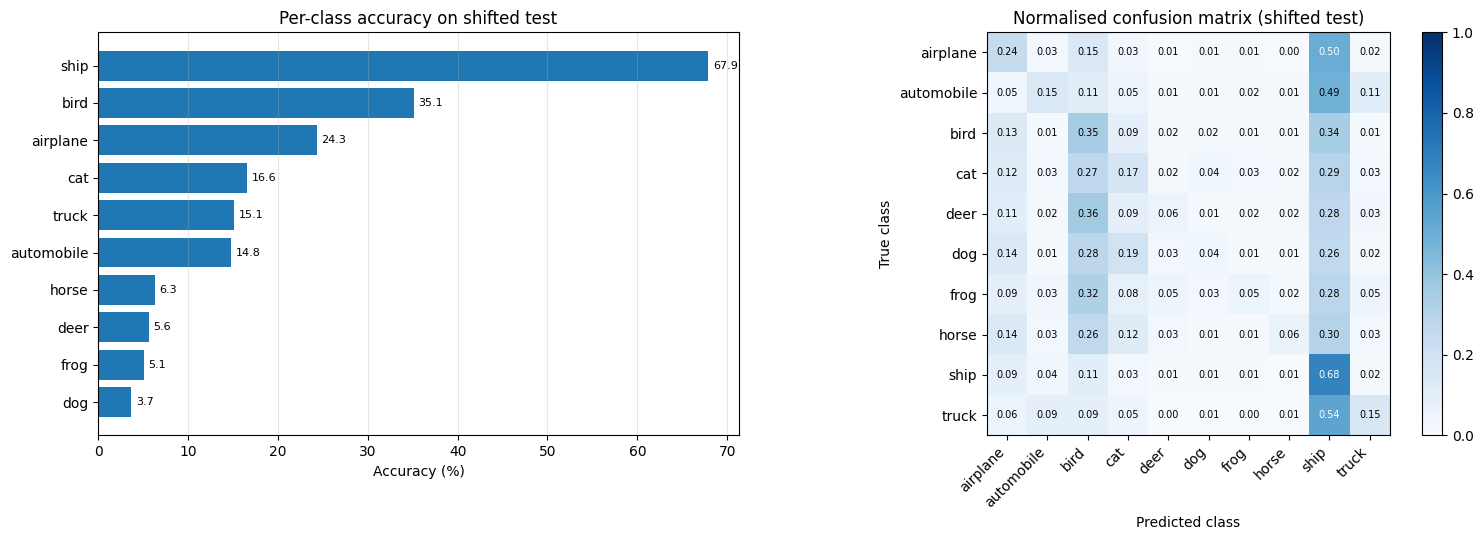

Most confused pairs (true -> predicted, fraction of true class):
  truck      -> ship        0.54
  airplane   -> ship        0.50
  automobile -> ship        0.49
  deer       -> bird        0.36
  bird       -> ship        0.34
  frog       -> bird        0.32


In [20]:
from sklearn.metrics import confusion_matrix
final_model = MODELS["Final model"][0]
P = predict(final_model, X_shift); pred = P.argmax(1)
cm = confusion_matrix(y_shift.numpy(), pred.numpy(), normalize="true")
per_class = cm.diagonal() * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
order = np.argsort(per_class)
ax[0].barh([CLASSES[i] for i in order], per_class[order], color="tab:blue")
for yy, v in enumerate(per_class[order]): ax[0].text(v + 0.5, yy, f"{v:.1f}", va="center", fontsize=8)
ax[0].set_xlabel("Accuracy (%)"); ax[0].set_title("Per-class accuracy on shifted test"); ax[0].grid(axis="x", alpha=0.3)
im = ax[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax[1].set_xticks(range(10)); ax[1].set_xticklabels(CLASSES, rotation=45, ha="right"); ax[1].set_yticks(range(10)); ax[1].set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        ax[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else "black")
ax[1].set_xlabel("Predicted class"); ax[1].set_ylabel("True class"); ax[1].set_title("Normalised confusion matrix (shifted test)")
plt.colorbar(im, ax=ax[1], fraction=0.046); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
print("Most confused pairs (true -> predicted, fraction of true class):")
for k in np.argsort(-off.ravel())[:6]:
    i, j = divmod(k, 10); print(f"  {CLASSES[i]:10s} -> {CLASSES[j]:10s}  {off[i, j]:.2f}")

### Part E.2 discussion 
Errors are dominated by a collapse onto a few default classes rather than classic fine-grained confusion.

Ship: it is predicted for 54% of trucks, 50% of airplanes and 49% of automobiles, and for 26–34% of the animal classes. It is also the best-recognised class at 67.9%.
Bird: it absorbs 26–36% of deer, frog, dog, cat and horse images.
Cat/dog: this pair is still confused (dog→cat 0.19). Dog recall is only 3.7% and cat 16.6%, since the two share body shape and texture, which blur and noise remove at 32×32.

A likely cause is that shifted images are dark, low-contrast and blurred, with a flat-colour occluding patch. They look like smooth sky or water scenes, which the model links to ship, airplane and bird. The matrix is consistent with this but does not prove it.

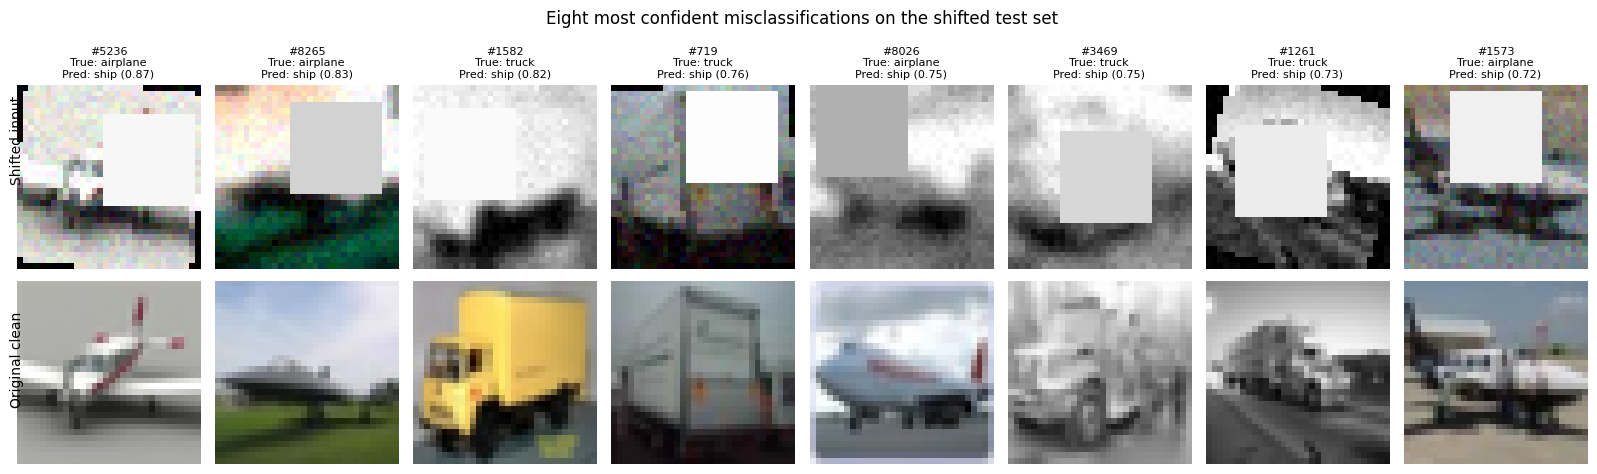

Misclassified image indices: [5236, 8265, 1582, 719, 8026, 3469, 1261, 1573]


In [21]:
wrong = np.where(pred.numpy() != y_shift.numpy())[0]
conf = P.max(1).values.numpy()
pick = wrong[np.argsort(-conf[wrong])][:8]          # the 8 most confident mistakes
fig, ax = plt.subplots(2, 8, figsize=(16, 5))
for k, i in enumerate(pick):
    ax[0, k].imshow(X_shift[i].permute(1, 2, 0)); ax[0, k].axis("off")
    ax[0, k].set_title(f"#{i}\nTrue: {CLASSES[int(y_shift[i])]}\nPred: {CLASSES[int(pred[i])]} ({conf[i]:.2f})", fontsize=8)
    ax[1, k].imshow(X_clean[i].permute(1, 2, 0)); ax[1, k].axis("off")
fig.text(0.005, 0.72, "Shifted input", rotation=90, va="center"); fig.text(0.005, 0.28, "Original clean", rotation=90, va="center")
plt.suptitle("Eight most confident misclassifications on the shifted test set"); plt.tight_layout(); plt.show()
print("Misclassified image indices:", pick.tolist())

### Part E.3 discussion (All eight are true airplane or truck images predicted as ship with 0.72–0.87 confidence.)

Image	True → Pred	Visual property that caused the failure
#5236	airplane → ship	The white occluding patch hides the tail and propeller. Over-exposure and noise leave only a dark horizontal fuselage on a light background, which looks like a hull.


#8265	airplane → ship	The grey patch removes the sky. Blur and low contrast turn the plane into a dark elongated blob over a greenish-teal base, like a hull on water.

#1582	truck → ship	The patch covers the cab, and grayscale removes the yellow colour cue. Only a dark horizontal blob at the bottom remains.

#719	truck → ship	The patch hides the upper box, and noise and brightening flatten the image. A dark lower band with no visible wheels reads as a hull.

#8026	airplane → ship	Grayscale, blur and a grey patch over the nose and sky leave a dark underside against a bright, hazy background (ship on sea).

#3469	truck → ship	Over-exposure and blur, plus a patch over the truck centre, leave a dark smudge in the lower-left corner.

#1261	truck → ship	Rotation leaves black corners, and the patch covers the truck body. Only a dark diagonal strip remains.

#1573	airplane → ship	Noise and a white patch over the tail and sky leave a low-contrast, horizontally elongated plane on a grey background.

Common cause: the corruptions remove what distinguishes the classes (wings, tail, cab, wheels, colour), and the model falls back on a coarse shortcut. That shortcut is a dark horizontal shape low in the image on a bright, smooth background, which it reads as a ship.

In [22]:
Xf = X_clean.float() / 255
tests = {
    "Clean test (reference)": X_clean,
    "Hidden stand-in only (gray / channel swap)": X_hidden,
    "Unseen: colour invert": TF.invert(X_clean),
    "Unseen: solarize": TF.solarize(X_clean, 128),
    "Unseen: posterize (3 bits)": TF.posterize(X_clean, 3),
    "Unseen: hue shift": (TF.adjust_hue(Xf, 0.35) * 255).round().byte(),
}
rows = []
for tname, Xt in tests.items():
    r = {"Test": tname}
    for mname in ["No augmentation", "Final model"]:
        a_ = [acc(m_, Xt, y_clean) for m_ in MODELS[mname]]
        r[mname] = f"{np.mean(a_):.1f} ± {np.std(a_):.1f}"
    rows.append(r)
display(pd.DataFrame(rows))

,Test,No augmentation,Final model
0,Clean test (reference),44.1 ± 2.8,41.0 ± 1.3
1,Hidden stand-in only (gray / channel swap),35.8 ± 2.2,32.7 ± 1.3
2,Unseen: colour invert,11.6 ± 0.8,10.6 ± 2.2
3,Unseen: solarize,24.2 ± 1.0,24.5 ± 2.4
4,Unseen: posterize (3 bits),41.7 ± 2.4,40.0 ± 1.5
5,Unseen: hue shift,30.1 ± 1.6,26.4 ± 2.1


### Part E.4 discussion hidden-corruption test

Using my stand-in corruption (random grayscale or channel swap), accuracy falls from 44.1 to 35.8 for the baseline and from 41.0 to 32.7 for the final model. Both lose 8.3 points, so the augmentation did not make the model more robust to this corruption, even though it trained with grayscale and channel shuffle at p = 0.2 each.

On the unseen corruptions the final model is no better than the baseline:

Invert: both are at chance (11.6 and 10.6).
Solarize: both are about equal (24.2 and 24.5).
Posterize: both barely change (41.7 and 40.0).
Hue shift: the final model is slightly worse (30.1 and 26.4).

In each case the final model’s accuracy drop from clean is about the same as the baseline’s, so the extra clean-accuracy loss explains the gap. With 3 seeds and std of 1–2 points, differences under about 3 points are not significant.

Conclusion: the augmentation helped on the combined shifted test (+3.3 points) but did not generalize to colour-type corruptions. Likely reasons are that the model underfits (train accuracy under augmentation is about 55–60%) and that the colour augmentations were applied with low probability. Stronger colour augmentation, or input standardization, would be needed. This is my reading of the numbers, not something I tested.

## Part F (bonus): Test-time augmentation

In [23]:
import time
def shift_img(x, dx, dy, p=2):
    xp = F.pad(x, (p, p, p, p), mode="reflect")
    return xp[:, :, p + dy:p + dy + 32, p + dx:p + dx + 32]

@torch.no_grad()
def predict_tta(model, X, views, bs=500):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = ((X[i:i+bs].float() / 255 - MEAN) / STD).to(DEVICE); pr = 0
        for flip, dx, dy in views:
            v = shift_img(xb.flip(3) if flip else xb, dx, dy)
            pr = pr + F.softmax(model(v), 1)
        out.append((pr / len(views)).cpu())
    return torch.cat(out)

def timed(fn):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.time(); o = fn()
    if DEVICE == "cuda": torch.cuda.synchronize()
    return o, time.time() - t

VIEW_SETS = {"No TTA (N=1)": [(0, 0, 0)],
             "Flip (N=2)": [(0, 0, 0), (1, 0, 0)],
             "Flip + 4 shifts (N=10)": [(f, dx, dy) for f in (0, 1) for dx, dy in [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)]]}
rows = []
for vname, views in VIEW_SETS.items():
    accs, times = [], []
    for m_ in MODELS["Final model"]:
        p_, t_ = timed(lambda: predict_tta(m_, X_shift, views))
        accs.append((p_.argmax(1) == y_shift).float().mean().item() * 100); times.append(t_)
    rows.append({"TTA": vname, "Shifted acc (%)": f"{np.mean(accs):.2f} ± {np.std(accs):.2f}", "Inference time (s, 10k imgs)": f"{np.mean(times):.2f}"})
tta_df = pd.DataFrame(rows); display(tta_df)

,TTA,Shifted acc (%),"Inference time (s, 10k imgs)"
0,No TTA (N=1),19.69 ± 0.88,0.48
1,Flip (N=2),19.70 ± 1.09,0.96
2,Flip + 4 shifts (N=10),19.74 ± 1.08,4.56


### Part F discussion
TTA gave essentially no gain: +0.01 points for N=2 and +0.05 for N=10, far inside the ±0.9–1.1 std. Cost grew about 2× and 9.5×. The likely reason is that flips and ±2 px shifts are already covered by the training augmentation, so the model is already nearly invariant to them. The dominant errors come from occlusion, low contrast and the collapse onto “ship”, and every view makes the same wrong decision, so averaging cannot fix it. TTA is not worth its cost here. Photometric views or a seed ensemble would be more promising.

## Final summary 

In [24]:
S = summarize("Final model")
print(f"Final shifted-test accuracy : {S['shifted'][0]:.2f} ± {S['shifted'][1]:.2f}  (3 seeds)")
print(f"Final clean-test accuracy   : {S['clean'][0]:.2f} ± {S['clean'][1]:.2f}")
print(f"Validation accuracy         : {S['val'][0]:.2f} ± {S['val'][1]:.2f}")
print("Configuration               :", FINAL_CFG)
print("Trainable parameters        :", n_params)
print("Single change with most gain:", best_change)

Final shifted-test accuracy : 19.69 ± 0.88  (3 seeds)
Final clean-test accuracy   : 40.99 ± 1.34
Validation accuracy         : 46.00 ± 1.41
Configuration               : {'geo': True, 'photo': True, 'cutout': True, 'mixup': 0.4, 'smooth': 0.1, 'drop': 0.4, 'wd': 0.0005}
Trainable parameters        : 242258
Single change with most gain: ('Geo + photo (vs best single)', np.float64(3.5066669185956343))
